In [ ]:
import os

# Change to "cuda" before the first PyRITE import; restart an existing kernel.
os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt

import pyrite

with mo.status.spinner(title="Preparing PyRITE reference tables"):
    _ = pyrite.fetch_tables()  # Fetch missing pinned tables once; reuse installed data.

tables_ready = True

# Your first X-ray spectrum

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/01-first-spectrum.py)

Set up PyRITE, simulate a small crystalline target, and plot its X-ray spectrum.

## Environment and reference tables

Locally, install the project environment and open this file with
`uv run marimo edit docs/notebooks/01-first-spectrum.py`.
In Molab, the inline dependencies provide the environment. Use its
**built-in package manager** to add packages; if table loading reports a
missing MF=26/MT=527 photon yield, enter `endf-parserpy==0.17.0` and restart.

The first cell calls `pyrite.fetch_tables()` to install about 100 MB of
pinned interaction data once; subsequent runs reuse the installed tables.
Start on CPU. For NVIDIA execution, add `pyrite-mc[nvidia]`, select an
available GPU in Molab (or use your local CUDA GPU), and set
`PYRITE_MC_BACKEND` to `cuda` **before importing PyRITE**. Restart the
kernel after changing the backend or installing CuPy.

## Simulate a crystalline target

This example uses 30 keV electrons incident upon a 100 nm HOPG slab.
The sampled electron histories do not represent a physical bunch population.
Use Pint quantities from `pyrite.units.ureg` for dimensional inputs.
PyRITE validates and normalizes them before numerical transport.

In [ ]:
from pyrite import simulate
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics
from pyrite.detectors import Detector
from pyrite.geometry import Footprint, Slab
from pyrite.units import ureg

# Quantities are checked at the API boundary; the simulation stays numeric.
beam = Beam(kinetic_energy=30 * ureg.keV, transverse=PointSpot(), longitudinal=PointBunch())
target = Slab(
    "hopg",
    thickness=100 * ureg.nm,
    tilt=30 * ureg.degree,
    footprint=Footprint(width=5 * ureg.mm, height=5 * ureg.mm),
)
detector = Detector(observation_angle=135 * ureg.degree)

numerics = Numerics(
    sampling=FixedSampling(cxr_electrons=32_768, brem_electrons=128),
    cxr_reflections=CxrReflections(n_families=2),
)

assert tables_ready  # Wait for reference-table installation before transport.
with mo.status.spinner(title="Simulating electron transport and X-ray spectrum"):
    result = simulate(beam, target, detector, numerics=numerics)

cxr = result.cxr.incoherent
brem = result.brem

## Plot the results

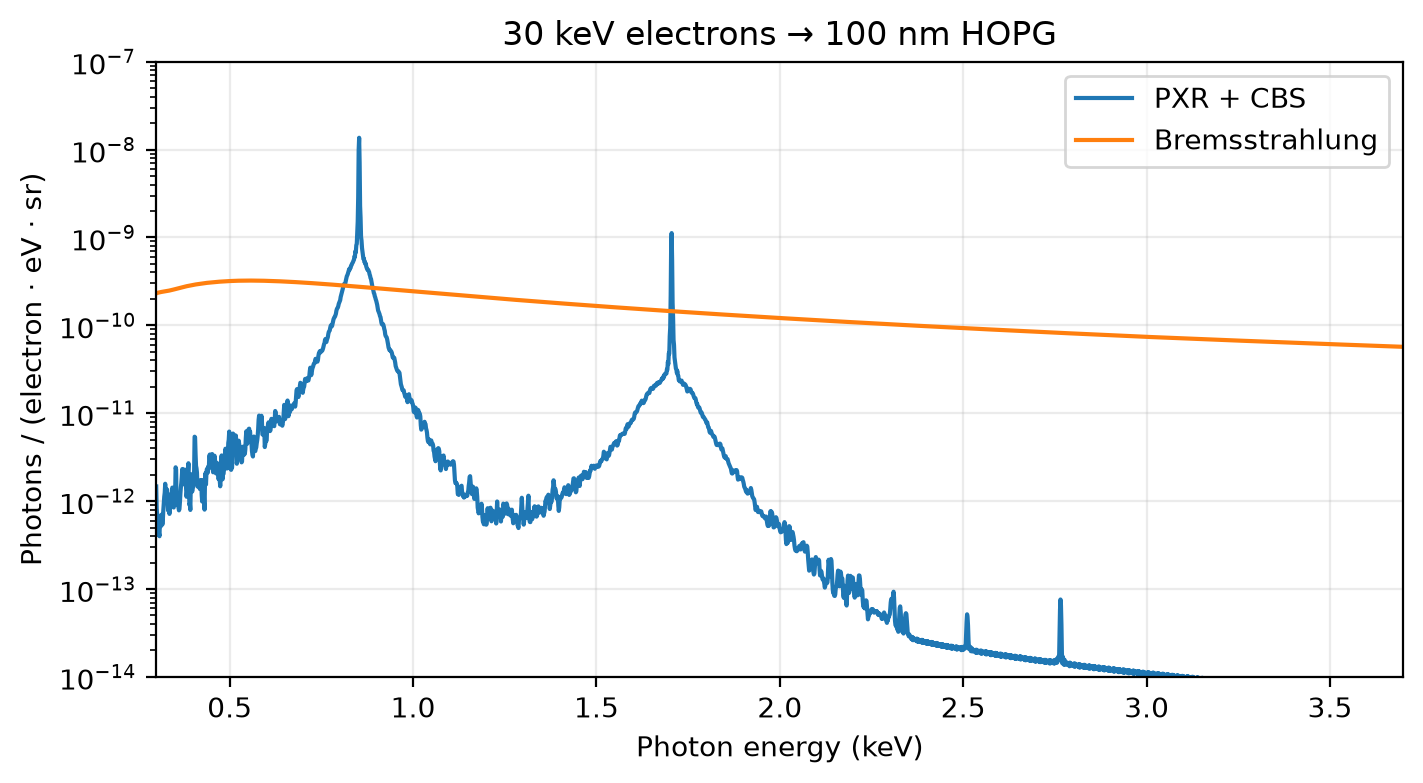

In [ ]:
figure, axis = plt.subplots(figsize=(7, 3.8), layout="constrained")
axis.plot(cxr.photon_energy_eV / 1_000, cxr.density, label="PXR + CBS")
axis.plot(brem.photon_energy_eV / 1_000, brem.density, label="Bremsstrahlung")
axis.set(
    xlabel="Photon energy (keV)",
    ylabel="Photons / (electron · eV · sr)",
    title="30 keV electrons → 100 nm HOPG",
    xlim=(0.3, 3.7),
    yscale="log",
    ylim=(1e-14, 1e-7),
)
axis.grid(alpha=0.25)
axis.legend()
figure  # noqa: B018 - marimo renders the final expression

## Interpretation

PXR and CBS are combined here because their amplitudes interfere. Their line
structure differs from the broad bremsstrahlung continuum. Each component is plotted
on its **native photon-energy grid**; adding array entries by index would mix
different energies. The vertical axis is source spectral density per incident
electron, per eV, per steradian. Integrating over photon energy gives
photons / (electron · sr). Multiplying by the electron rate and accepted
solid angle gives an expected photon rate in photons / s.

Try doubling the history counts, then change only the target thickness. Keep a
record of the resolved seed when comparing configurations; different backends need not produce
identical random trajectories. Continue to notebook 02 to separate source
yields from beam-current-scaled photon rates. Notebook 03 predicts vacuum line
energies; the [results how-to](https://pyrite.readthedocs.io/en/latest/guides/working-with-results.html)
covers saved checkpoints. See
[model limitations](https://pyrite.readthedocs.io/en/latest/physics/capabilities.html)
and [validation status](https://pyrite.readthedocs.io/en/latest/validation/status-summary.html)
before interpreting these small-sample results quantitatively.

## Continue learning

Next: [Understanding simulation results](02-understanding-results.ipynb).
For installation and table acquisition, use [Getting started](../../guides/getting-started.md).
Consult the [scene API](../../reference/python-api/core.md) for object contracts,
[spectral observables](../../physics/radiation-physics/spectral-observables.md)
for normalization, and [validation status](../../validation/status-summary.md)
for the evidence behind the selected models.

{download}`Download canonical Marimo notebook <../01-first-spectrum.py>`